# DATA SCIENCE INTERN @OASIS INFOBYTE

## AUTHOR : SHREENIDHI MEDAR

# Task 1 · IRIS FLOWER CLASSIFICATION

##  1. Importing necessary libraries

In [1]:
# General-purpose libraries for data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')


## 2. Loading the Dataset

In [2]:
# Import the built-in Iris dataset only when we are ready to load it
from sklearn.datasets import load_iris

# Load as a pandas DataFrame
iris = load_iris(as_frame=True)
df = iris.frame.copy()
print("Dataset loaded")

Dataset loaded


In [3]:
# Add a readable species name column (0 = setosa, 1 = versicolor, 2 = virginica)
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

feature_cols = iris.feature_names
print('Features:', feature_cols)
print('Classes :', list(iris.target_names))
df.head()


Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes : ['setosa', 'versicolor', 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Data Preprocessing and Quality Checks

We will verify its structure, data types, missing values, duplicate records and value ranges before analysis. 

In [4]:
# Shape of the dataset (rows, columns)
print('Shape:', df.shape)

Shape: (150, 6)


In [5]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
 5   species            150 non-null    object 
dtypes: float64(4), int32(1), object(1)
memory usage: 6.6+ KB


In [6]:
# Null value check
print('Missing values per column:')
print(df.isnull().sum())
print('Total missing values:', df.isnull().sum().sum())

# Duplicate rows check
print('Duplicate rows:', df.duplicated().sum())

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64
Total missing values: 0
Duplicate rows: 1


In [7]:
# Descriptive statistics for all features
df[feature_cols].describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [8]:
# Class balance
print(df['species'].value_counts())

# Mean of each feature per species - a quick preview of what separates the classes
df.groupby('species')[feature_cols].mean().round(2)

setosa        50
versicolor    50
virginica     50
Name: species, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


## 4. Exploratory Data Analysis (EDA)

### 4.1 Pairplot - feature distributions and relationships by species

C:\Users\Shreenidhi Medar\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


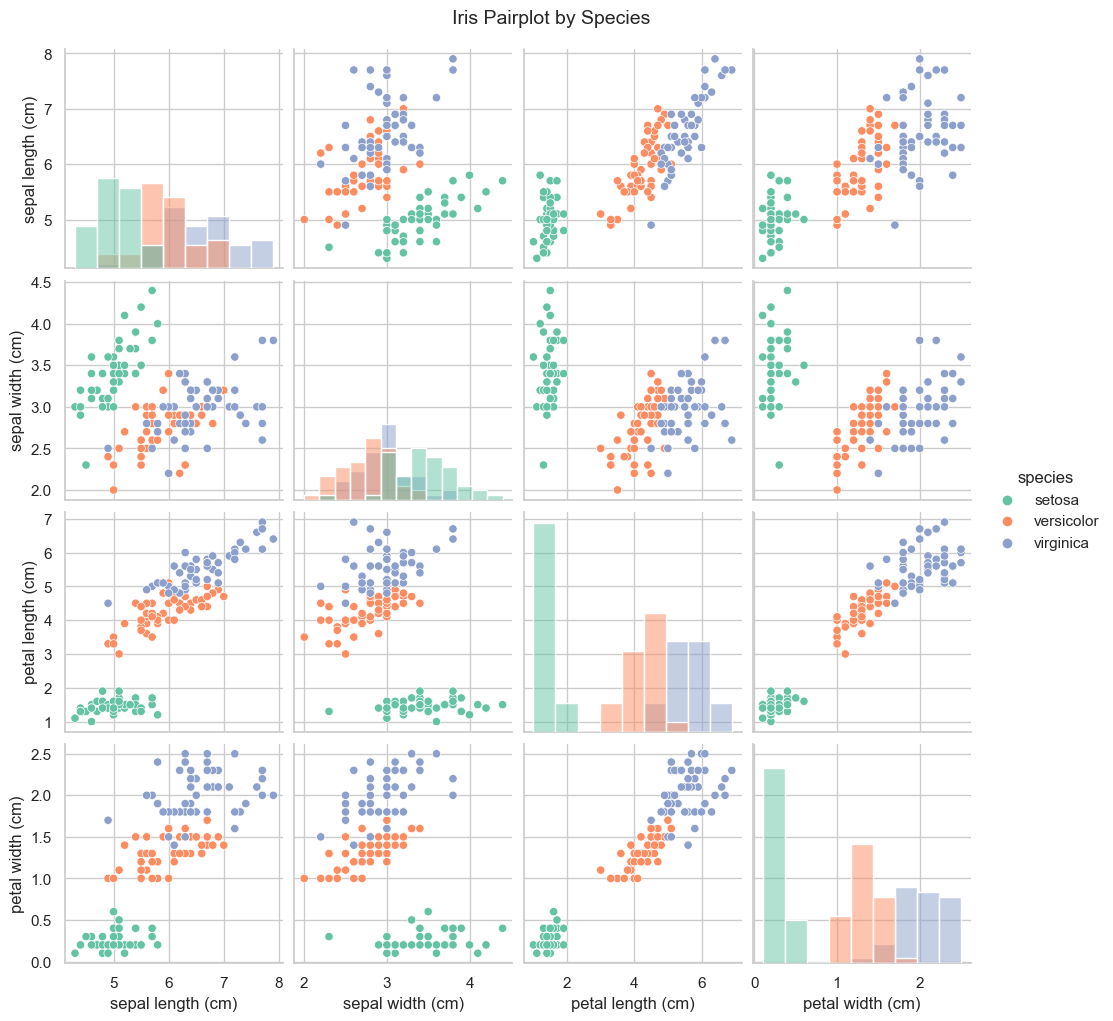

In [9]:
# Pairplot: scatter plots between every feature pair + distribution on the diagonal
g = sns.pairplot(df.drop(columns='target'), hue='species',
                 palette='Set2', diag_kind='hist', corner=False)
g.fig.suptitle('Iris Pairplot by Species', y=1.02, fontsize=14)
plt.show()

### 4.2 Box plots - each feature by species

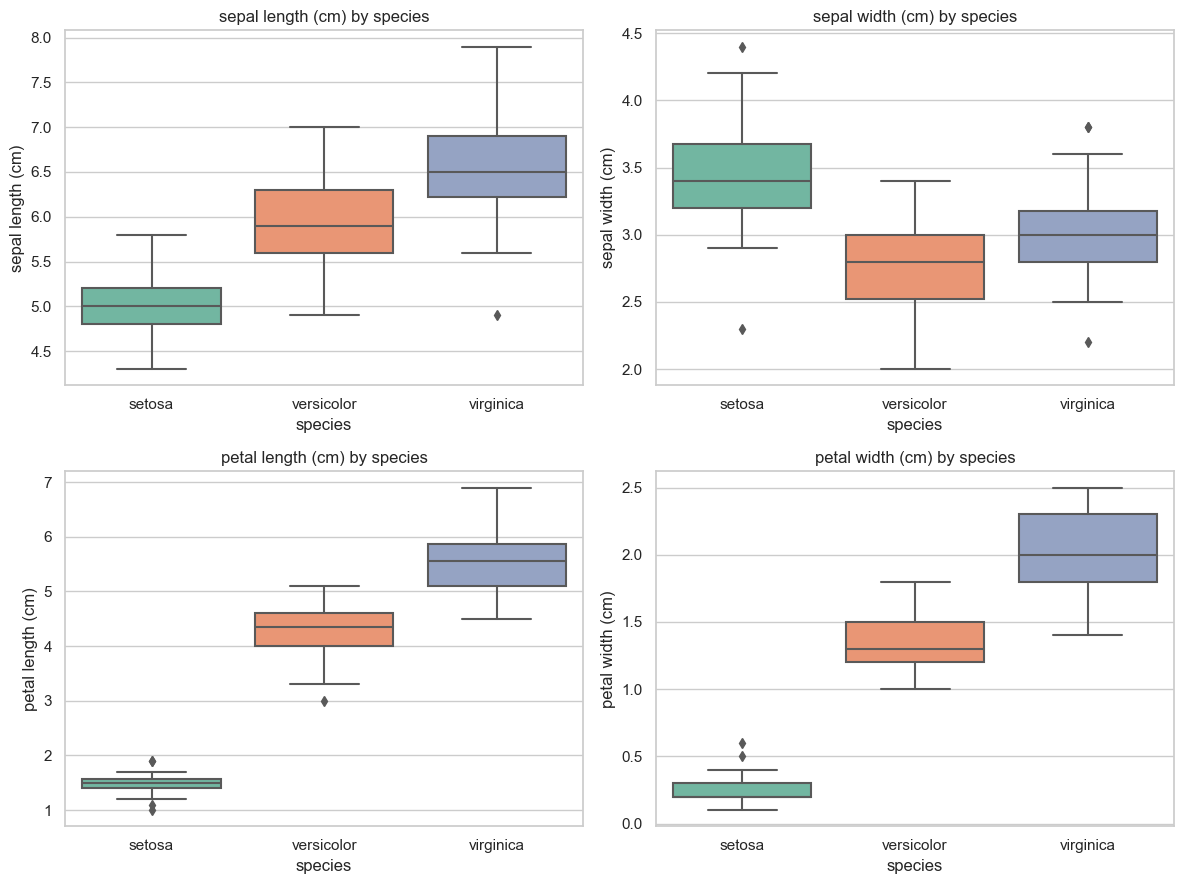

In [10]:
# One box plot per feature, split by species
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.boxplot(data=df, x='species', y=col, palette='Set2', ax=ax)
    ax.set_title(f'{col} by species')
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

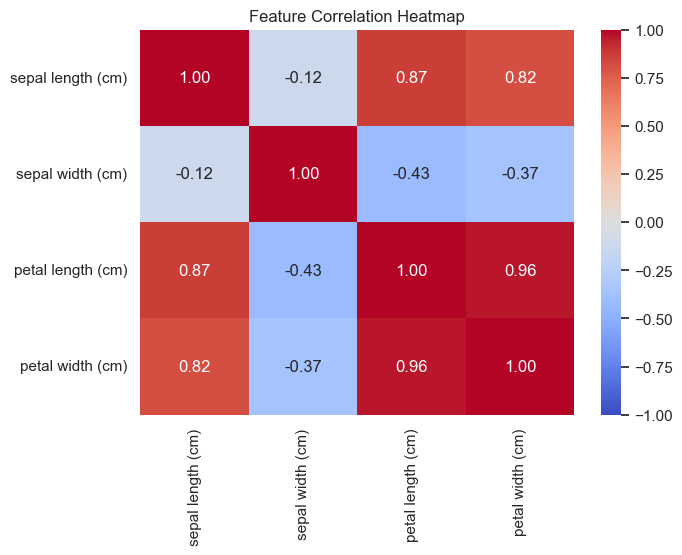

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[feature_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.show()

## 5. Feature Selection Discussion

In [12]:
# Libraries needed for feature selection analysis
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

X_all = df[feature_cols]
y_all = df['target']

# 1) Correlation of each feature with the target
corr_with_target = X_all.corrwith(y_all).abs()

# 2) Mutual information between each feature and the target
mi = pd.Series(mutual_info_classif(X_all, y_all, random_state=42), index=feature_cols)

# 3) Random Forest feature importance
rf_tmp = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_all, y_all)
rf_imp = pd.Series(rf_tmp.feature_importances_, index=feature_cols)

feature_scores = pd.DataFrame({
    'Abs Correlation': corr_with_target,
    'Mutual Information': mi,
    'RF Importance': rf_imp
}).round(3).sort_values('RF Importance', ascending=False)

feature_scores


,Abs Correlation,Mutual Information,RF Importance
petal length (cm),0.949,0.993,0.459
petal width (cm),0.957,0.986,0.418
sepal length (cm),0.783,0.511,0.102
sepal width (cm),0.427,0.299,0.021


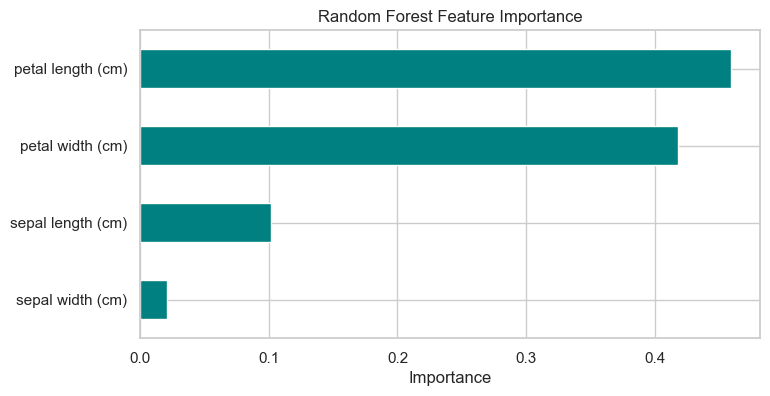

In [13]:
# Plot the Random Forest importances
rf_imp.sort_values().plot(kind='barh', figsize=(8, 4), color='teal')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.show()

## 6. Train/Test Split 

In [14]:
# Machine-learning preparation libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = df[feature_cols]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training set:', X_train.shape)
print('Test set    :', X_test.shape)
print('Test class counts:', y_test.value_counts().sort_index().to_dict())


Training set: (120, 4)
Test set    : (30, 4)
Test class counts: {0: 10, 1: 10, 2: 10}


## 7. Model Training

Four classifiers are trained.

Logistic Regression,KNN, DecisionTree and RandomForest

In [15]:
# Classification algorithms used in this project
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'K-Nearest Neighbours': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
}

# Fit every model on the training data
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'Trained: {name}')


Trained: Logistic Regression
Trained: K-Nearest Neighbours
Trained: Decision Tree
Trained: Random Forest


## 8. Model Evaluation

For every model: accuracy score, classification report (precision, recall, F1) and confusion matrix on the **test set**.

In [16]:
# Evaluation metrics for classification performance
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

class_names = list(iris.target_names)
test_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    test_results[name] = acc

    print('=' * 60)
    print(f'{name}  |  Test Accuracy: {acc:.4f}')
    print('=' * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))


Logistic Regression  |  Test Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

K-Nearest Neighbours  |  Test Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Decision Tree  |  Test Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000       

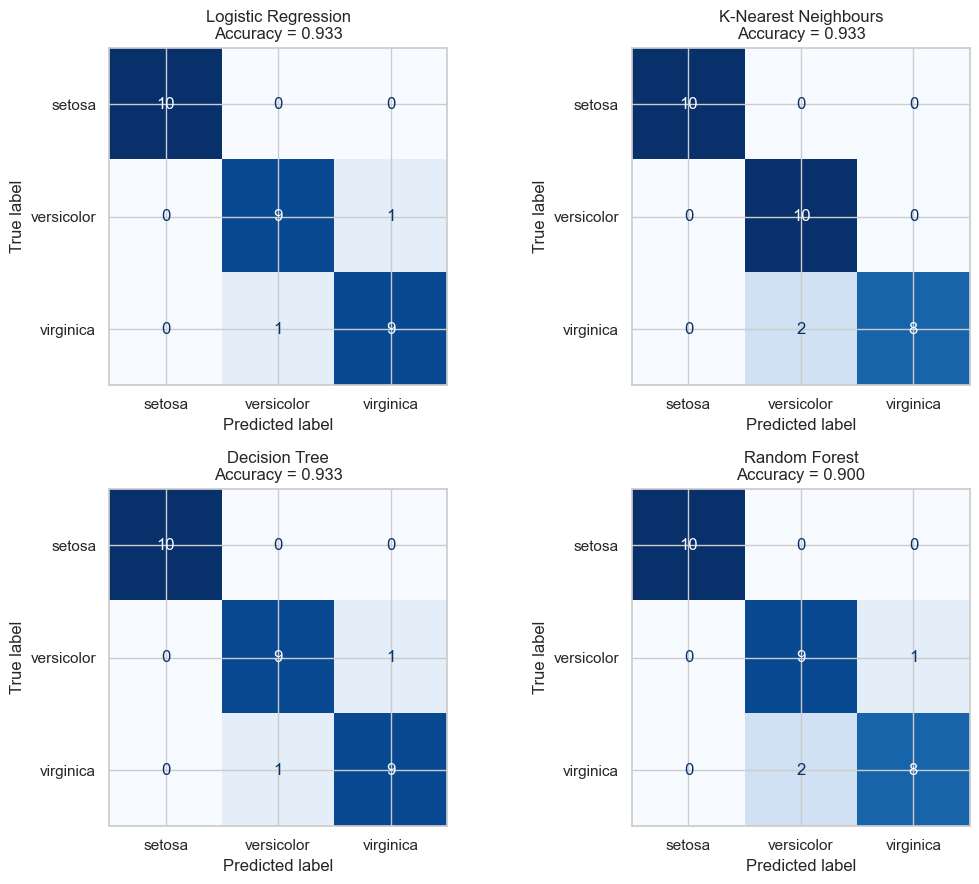

In [17]:
# Confusion matrices for all models side by side
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, model) in zip(axes.ravel(), models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\nAccuracy = {test_results[name]:.3f}')

plt.tight_layout()
plt.show()

## 9. Cross-Validation 

The test set has only 30 samples, so one wrong prediction changes accuracy by about 3.3%. A single split is too noisy to pick a winner reliably. 5-fold stratified cross-validation on all 150 samples gives a more trustworthy comparison.

In [18]:
# Cross-validation tools for a more stable model comparison
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    rows.append({
        'Model': name,
        'Test Accuracy': round(test_results[name], 4),
        'CV Mean Accuracy': round(scores.mean(), 4),
        'CV Std': round(scores.std(), 4),
    })

summary = pd.DataFrame(rows).set_index('Model')
summary.sort_values(['CV Mean Accuracy', 'Test Accuracy'], ascending=False)


,Test Accuracy,CV Mean Accuracy,CV Std
Model,,,
K-Nearest Neighbours,0.9333,0.9733,0.0249
Random Forest,0.9000,0.9600,0.0389
Logistic Regression,0.9333,0.9533,0.0452
Decision Tree,0.9333,0.9533,0.0340


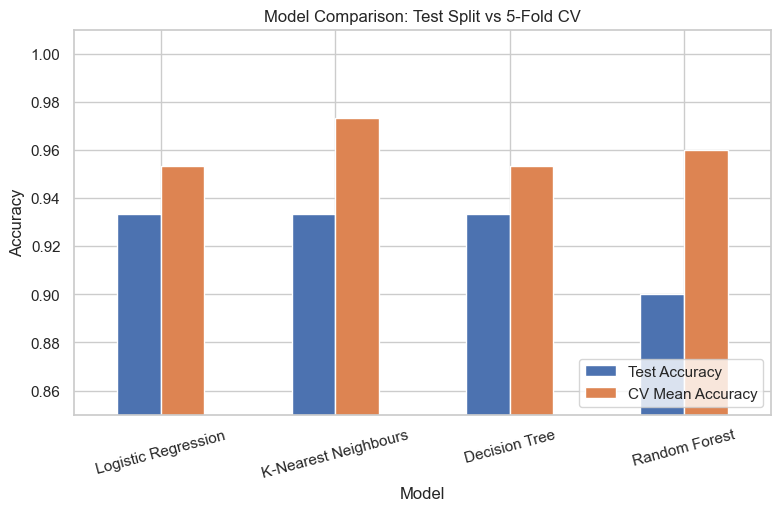

In [19]:
# Visual comparison
summary[['Test Accuracy', 'CV Mean Accuracy']].plot(kind='bar', figsize=(9, 5), rot=15)
plt.ylim(0.85, 1.01)
plt.ylabel('Accuracy')
plt.title('Model Comparison: Test Split vs 5-Fold CV')
plt.legend(loc='lower right')
plt.show()

## 10. Best Model Declaration

In [20]:
# Rank by CV mean accuracy first (more reliable), then test accuracy, then lower CV std (more stable)
ranked = summary.sort_values(['CV Mean Accuracy', 'Test Accuracy', 'CV Std'],
                             ascending=[False, False, True])
best_name = ranked.index[0]

print(f'BEST MODEL: {best_name}')
print(ranked.loc[best_name])
print()
print('Gap between best and worst model (CV accuracy): '
      f"{(ranked['CV Mean Accuracy'].max() - ranked['CV Mean Accuracy'].min()) * 100:.2f} percentage points")

BEST MODEL: K-Nearest Neighbours
Test Accuracy       0.9333
CV Mean Accuracy    0.9733
CV Std              0.0249
Name: K-Nearest Neighbours, dtype: float64

Gap between best and worst model (CV accuracy): 2.00 percentage points


## 11. Bonus: Predict a New Flower

In [21]:
# Predict the species of a new, unseen flower using the best model
new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=feature_cols)
pred = models[best_name].predict(new_flower)[0]
print(f'Measurements: {new_flower.values.tolist()[0]}')
print(f'Predicted species ({best_name}): {class_names[pred]}')

Measurements: [5.9, 3.0, 5.1, 1.8]
Predicted species (K-Nearest Neighbours): virginica


## THANK YOU